### Current baseline assumptions

Each innocent player starts with equal probability that any other player is Mafia. Private investigation results use a symmetric noise model: the result is correct with probability `reliability`, which the detective knows.

For a public accusation, `receive_accusation()` tests each possible Mafia identity and assigns a likelihood to the observed message:

- If the speaker is Mafia: `1/3`, assuming a random accusation against one of the other three players.
- If the speaker is innocent and accuses Mafia: `prob_innocent_finds_mafia`, currently `0.5`.
- If the speaker is innocent and accuses another innocent: `(1 - prob_innocent_finds_mafia) / 2`, currently `0.25` for each of the two innocent alternatives.

The agent multiplies each prior by its likelihood and normalizes. Repeated identical accusations from the same speaker are ignored. New accusations are processed as additional evidence without explicitly modeling their dependence on earlier discussion; message confidence is not used.

These are assumptions used by the observer, not measured detection rates. Actual innocent players accuse a highest-belief target, while Mafia targets an innocent with the most previous accusations, so the likelihood model does not exactly match the speaking policies. This is an approximate Bayesian baseline, not an optimal agent.

Equal-probability targets are chosen randomly. Final voting ties still count as Mafia wins.

### Discussion rounds

Set `discussion_rounds` in the simulation cell to `1`, `2`, or `3`. Each game has one investigation, the selected number of discussion rounds, and one final vote. Every player speaks once per round, with speaking order shuffled again each round. Beliefs and accusation history carry over between rounds. Repeated identical accusations from the same speaker still do not add evidence. The default remains one round for comparison with the previous notebook.

In [24]:
import random

#Assumed innocent accusation accuracy, not a measured rate
prob_innocent_finds_mafia = 0.5

class Villager:
  def __init__(self, id, players):
    self.id = id
    self.players = players

    self.possible_mafia = [p for p in players if p!=self.id]
    self.beliefs = [1 / len(self.possible_mafia) for p in players]
    self.beliefs[id] = 0

    self.history = []

  def receive_detective(self, target, result, reliability):
    self.target = target
    self.result = result
    self.reliability = reliability
    self.update_beliefs(target, result, reliability)

  def update_beliefs(self, target, result, reliability):
    for mafia in self.possible_mafia:
      if mafia==target:
        if result==1: #Is Mafia
          likelihood = reliability
        else:
          likelihood = 1 - reliability
      else:
        if result==1: #Is Mafia
          likelihood = 1 - reliability
        else:
          likelihood = reliability
      self.beliefs[mafia] = self.beliefs[mafia] * likelihood

    total = 0.0
    for b in self.beliefs:
      total += b
    self.beliefs = [b / total for b in self.beliefs]

  def vote(self):
    maxp = -1
    max_players = []

    for player in range(len(self.beliefs)):
      if self.beliefs[player] > maxp:
        maxp = self.beliefs[player]
        max_players = [player]
      elif self.beliefs[player] == maxp:
        max_players += [player]
    return random.choice(max_players)

  def generate_message(self):
    target=self.vote()
    return {"accused_player": target, "confidence": self.beliefs[target]}

  def receive_accusation(self, speaker, accused):
    if (speaker, accused) in self.history:
      return
    for mafia in self.possible_mafia:
      if speaker==mafia:
        likelihood = 1/3 #Observer assumes random Mafia accusations
      elif accused==mafia:
        likelihood = prob_innocent_finds_mafia
      else:
        likelihood = (1 - prob_innocent_finds_mafia) / 2
      self.beliefs[mafia] = self.beliefs[mafia] * likelihood
    total = 0.0
    for b in self.beliefs:
      total += b
    self.beliefs = [b / total for b in self.beliefs]
    self.history += [(speaker, accused)]



In [25]:
class Detective(Villager):
  def __init__(self, id, players):
    super().__init__(id, players)
    self.investigations = []
    self.revealed_investigations = []

  def choose_investigation(self):
    uninvestigated = [p for p in self.players if p != self.id and p not in [inv[0] for inv in self.investigations]]
    if len(uninvestigated)==0:
      return None

    maxp = -1
    max_players = []

    for player in uninvestigated:
      if self.beliefs[player] > maxp:
        maxp = self.beliefs[player]
        max_players = [player]
      elif self.beliefs[player] == maxp:
        max_players += [player]
    return random.choice(max_players)

  def receive_investigation(self, target, result, reliability):
    self.investigations += [(target, result, reliability)]
    self.update_beliefs(target, result, reliability)

  def decide_reveal(self):
    if len(self.investigations) == 0: return None
    (target, result, reliability) = self.investigations[-1]
    if (target, result, reliability) in self.revealed_investigations: return None
    if result == 1: # and reliability >= 0.8:
      self.revealed_investigations += [(target, result, reliability)]
      #return {"claim_detective":True, "investigated_player": target, "result": result, "reliability": reliability}
      return {"accused_player": target, "confidence": reliability}
    else:
      return None

  def generate_message(self):
    temp = self.decide_reveal()
    if temp != None:
      return temp
    else:
      return super().generate_message()

In [26]:
import random
class Mafia():
  def __init__(self, id, players):
    self.id = id
    self.players = players
    self.innocent_players = [p for p in players if p!=self.id]
    self.accusation_history = []
    self.current_target = None

  def receive_accusation(self, speaker, accused):
    if speaker==accused or (speaker, accused) in self.accusation_history:
      return
    self.accusation_history += [(speaker, accused)]

  def choose_target(self):
    accusation_counts = {}
    for p in self.innocent_players:
      accusation_counts[p] = 0
    for (speaker, accused) in self.accusation_history:
      if accused in self.innocent_players:
        accusation_counts[accused] += 1
    max_count = -1
    max_player = []
    for p in self.innocent_players:
      if accusation_counts[p] > max_count:
        max_count = accusation_counts[p]
        max_player = [p]
      elif accusation_counts[p] == max_count:
        max_player += [p]
    if len(max_player) == 1:
      return max_player[0]
    else:
      return random.choice(max_player)

  def generate_message(self):
    self.current_target = self.choose_target()
    return {"accused_player": self.current_target, "confidence": 0.8}

  def vote(self):
    if self.current_target != None:
      return self.current_target
    return self.choose_target()


In [27]:
class Game:
  def __init__(self, reliability, discussion_rounds=1):
    if not isinstance(discussion_rounds, int) or discussion_rounds < 1:
      raise ValueError("discussion_rounds must be a positive integer")
    self.discussion_rounds = discussion_rounds
    self.players = [i for i in range(4)]
    assignments = [i for i in range(4)]
    random.shuffle(assignments)
    self.villagers = [Villager(i, self.players) for i in assignments[:2]]
    self.detective = Detective(assignments[2], self.players)
    self.mafia = Mafia(assignments[3], self.players)
    self.agents = {}
    for agent in self.villagers + [self.detective, self.mafia]:
      self.agents[agent.id] = agent
    self.mafia_id = assignments[3]
    self.detective_id = assignments[2]
    self.public_messages = []
    self.reliability = reliability
    self.votes = {}

  def investigation(self):
    target = self.detective.choose_investigation()
    if target == None:
      return

    actual_result = 0
    if target==self.mafia_id:
      actual_result = 1
    if random.random() < self.reliability:
      observed = actual_result
    else:
      observed = 1 - actual_result

    self.detective.receive_investigation(target, observed, self.reliability)

  def discussion(self):
    order = self.players.copy()
    random.shuffle(order)
    for p in order:
      message = self.agents[p].generate_message()
      self.public_messages += [(p, message)]

      for p1 in self.players:
        if p != p1:
          self.agents[p1].receive_accusation(p, message["accused_player"])
  def vote(self):
    self.votes = {}
    for p in self.players:
      target = self.agents[p].vote()
      self.votes[p] = target

    vote_counts = {}
    for p in self.players:
      vote_counts[p] = 0
    for target in self.votes.values():
      vote_counts[target] += 1
    max_count = max(vote_counts.values())
    max_players = []
    for p in self.players:
      if vote_counts[p] == max_count:
        max_players += [p]
    if len(max_players) > 1: return None
    return max_players[0]

  def winner(self, eliminated_player):
    if eliminated_player == self.mafia_id:
      return "Villager"
    else:
      return "Mafia"

  def play(self):
    self.investigation()
    for round in range(self.discussion_rounds):
      self.discussion()
    eliminated = self.vote()
    winner = self.winner(eliminated)
    return {"winner":winner, "eliminated":eliminated, "votes":self.votes, "public_messages":self.public_messages}




100%|██████████| 21/21 [00:05<00:00,  3.58it/s]

Reliability: 0 , Villager Win Rate: 0.2517
Reliability: 0.05 , Villager Win Rate: 0.2404
Reliability: 0.1 , Villager Win Rate: 0.2312
Reliability: 0.15 , Villager Win Rate: 0.2265
Reliability: 0.2 , Villager Win Rate: 0.2128
Reliability: 0.25 , Villager Win Rate: 0.192
Reliability: 0.3 , Villager Win Rate: 0.1935
Reliability: 0.35 , Villager Win Rate: 0.2036
Reliability: 0.4 , Villager Win Rate: 0.2136
Reliability: 0.45 , Villager Win Rate: 0.2277
Reliability: 0.5 , Villager Win Rate: 0.229
Reliability: 0.55 , Villager Win Rate: 0.2448
Reliability: 0.6 , Villager Win Rate: 0.26
Reliability: 0.65 , Villager Win Rate: 0.2725
Reliability: 0.7 , Villager Win Rate: 0.3448
Reliability: 0.75 , Villager Win Rate: 0.3636
Reliability: 0.8 , Villager Win Rate: 0.3943
Reliability: 0.85 , Villager Win Rate: 0.4297
Reliability: 0.9 , Villager Win Rate: 0.4456
Reliability: 0.95 , Villager Win Rate: 0.4691
Reliability: 1.0 , Villager Win Rate: 0.5078


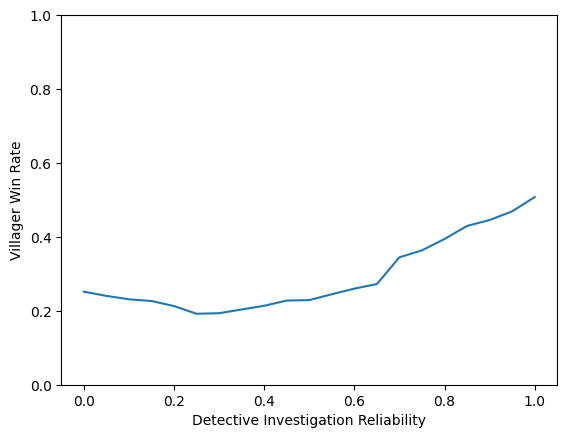

In [28]:
import matplotlib.pyplot as plt
from tqdm import tqdm

results = {}
reliabilities = [0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0]
num_games = 10000
discussion_rounds = 1 #Change to 2 or 3 for more discussion

for reliability in tqdm(reliabilities):
  villager_wins = 0

  for i in range(num_games):
    game = Game(reliability, discussion_rounds)
    result = game.play()
    if result["winner"] == "Villager":
      villager_wins += 1
  results[reliability] = villager_wins / num_games

for reliability, win_rate in results.items():
  print("Reliability:", reliability, ", Villager Win Rate:", win_rate)

plt.plot(list(results.keys()), list(results.values()))
plt.xlabel("Detective Investigation Reliability")
plt.ylabel("Villager Win Rate")
plt.ylim(0,1)
plt.show()

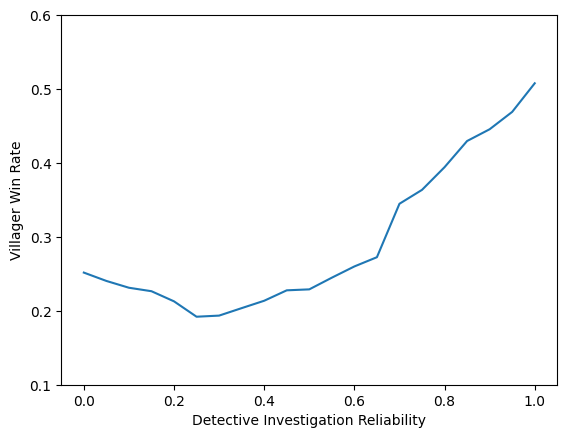

In [29]:
plt.plot(list(results.keys()), list(results.values()))
plt.xlabel("Detective Investigation Reliability")
plt.ylabel("Villager Win Rate")
plt.ylim(0.1,0.6)
plt.show()

### Experiment: comparing discussion rounds

We compare one, two, and three discussion rounds across the same investigation reliabilities. Only the number of discussion rounds changes: agent policies, one private investigation, one final vote, and Mafia winning voting ties stay fixed.

Run the agent and Game definition cells first. This section uses its own settings and `round_comparison_results`, leaving the earlier sweep and its results untouched. With 10,000 games per configuration, the full comparison runs 630,000 games.

Each game uses seed `comparison_seed + comparison_i`, reused across configurations to match initial role assignments, investigation targets, and investigation random draws. Later random choices can diverge as the games progress. The previous random state is restored when the experiment finishes. Re-running these cells with the same settings reproduces the comparison.

Repeated identical accusations are still ignored. The plot is descriptive; small differences need further checks before drawing conclusions.

In [30]:
import random
import matplotlib.pyplot as plt
from tqdm import tqdm

comparison_rounds = [1, 2, 3]
comparison_reliabilities = [i / 20 for i in range(21)]
comparison_num_games = 10000
comparison_seed = 42
round_comparison_results = {}

comparison_random_state = random.getstate()
try:
  for comparison_n_rounds in tqdm(comparison_rounds):
    round_comparison_results[comparison_n_rounds] = {}

    for comparison_reliability in comparison_reliabilities:
      comparison_wins = 0

      for comparison_i in range(comparison_num_games):
        random.seed(comparison_seed + comparison_i)
        comparison_game = Game(comparison_reliability, comparison_n_rounds)
        comparison_result = comparison_game.play()
        if comparison_result["winner"] == "Villager":
          comparison_wins += 1

      round_comparison_results[comparison_n_rounds][comparison_reliability] = comparison_wins / comparison_num_games

    print("Discussion rounds:", comparison_n_rounds, ", Win rate with accurate investigation:", round_comparison_results[comparison_n_rounds][1.0])
finally:
  random.setstate(comparison_random_state)


 33%|███▎      | 1/3 [00:07<00:14,  7.31s/it]

Discussion rounds: 1 , Win rate with accurate investigation: 0.4961


 67%|██████▋   | 2/3 [00:16<00:08,  8.60s/it]

Discussion rounds: 2 , Win rate with accurate investigation: 0.5097


100%|██████████| 3/3 [00:27<00:00,  9.15s/it]

Discussion rounds: 3 , Win rate with accurate investigation: 0.5097


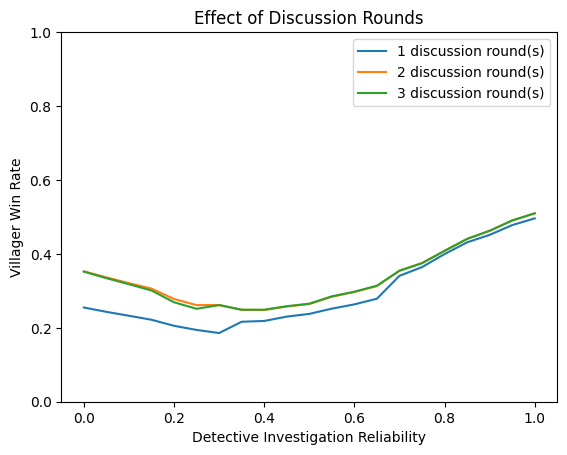

In [31]:
plt.figure()
for comparison_n_rounds, comparison_rates in round_comparison_results.items():
  plt.plot(list(comparison_rates.keys()), list(comparison_rates.values()), label=str(comparison_n_rounds) + " discussion round(s)")

plt.xlabel("Detective Investigation Reliability")
plt.ylabel("Villager Win Rate")
plt.title("Effect of Discussion Rounds")
plt.ylim(0,1)
plt.legend()
plt.show()


### Detective claims and fabricated reports

The detective reports its actual investigation result on its first turn, even when the result says innocent. Mafia makes one fabricated positive report against an innocent chosen by its existing targeting policy. Later turns use ordinary accusations. Everyone shares the same structured message format; the engine relays claims without authenticating them. Truthful reporting means reporting the received signal, which may itself be wrong.

Innocent agents track probabilities over possible (Mafia, Detective) assignments, using only their own role, their private signal if any, and public messages. A claimant must be either Detective or Mafia. A genuine report has likelihood q/3 when correct or (1-q)/3 when incorrect; the 1/3 models uniform investigation target selection. A fabricated report is assumed to name each other player with probability 1/3 and to be positive. Actual Mafia targeting remains strategic, so this component is approximate. Ordinary accusations retain the original fixed likelihood assumptions.

Each claim is processed once, not also as an ordinary accusation. Identical reports are not counted again. Agents do not infer roles from silence or from missing claims.

Because only Detective and Mafia claim, two claimants reveal that the other players are villagers under these policies. A detective also knows that another claimant is Mafia. These are consequences of the policy assumptions, not access to hidden engine state. Even at q=0.5, claims can reveal role information although the investigation signal is uninformative.

Each game has one investigation, configurable discussion rounds, and one final vote; ties go to Mafia. This tests a fixed early-disclosure policy, not optimal disclosure timing or unrestricted deception.

In [32]:
class ClaimVillager(Villager):
  def __init__(self, id, players, reliability, is_detective=False):
    super().__init__(id, players)
    self.reliability = reliability
    self.role_beliefs = {}
    self.claim_history = []
    for mafia in self.possible_mafia:
      for detective in players:
        if detective == mafia: continue
        if is_detective and detective != self.id: continue
        if not is_detective and detective == self.id: continue
        self.role_beliefs[(mafia, detective)] = 1
    self.normalize_roles()

  def normalize_roles(self):
    total = sum(self.role_beliefs.values())
    if total == 0:
      raise ValueError("Messages contradict all remaining role assignments")
    self.role_beliefs = {roles: p / total for roles, p in self.role_beliefs.items()}
    self.beliefs = [0 for p in self.players]
    for (mafia, detective), p in self.role_beliefs.items():
      self.beliefs[mafia] += p

  def update_beliefs(self, target, result, reliability):
    for mafia, detective in self.role_beliefs:
      likelihood = reliability if result == int(target == mafia) else 1 - reliability
      self.role_beliefs[(mafia, detective)] *= likelihood
    self.normalize_roles()

  def receive_accusation(self, speaker, accused):
    if (speaker, accused) in self.history: return
    for mafia, detective in self.role_beliefs:
      if speaker == mafia:
        likelihood = 1/3
      elif accused == mafia:
        likelihood = prob_innocent_finds_mafia
      else:
        likelihood = (1 - prob_innocent_finds_mafia) / 2
      self.role_beliefs[(mafia, detective)] *= likelihood
    self.normalize_roles()
    self.history += [(speaker, accused)]

  def receive_message(self, speaker, message):
    if not message.get("claim_detective", False):
      self.receive_accusation(speaker, message["accused_player"])
      return

    target = message["investigated_player"]
    result = message["result"]
    claim = (speaker, target, result)
    if claim in self.claim_history: return

    for mafia, detective in self.role_beliefs:
      if speaker == detective:
        likelihood = self.reliability / 3 if result == int(target == mafia) else (1 - self.reliability) / 3
      elif speaker == mafia:
        likelihood = 1/3 if result == 1 and target != mafia else 0
      else:
        likelihood = 0
      self.role_beliefs[(mafia, detective)] *= likelihood
    self.normalize_roles()
    self.claim_history += [claim]


class ClaimDetective(ClaimVillager):
  def __init__(self, id, players, reliability):
    super().__init__(id, players, reliability, is_detective=True)
    self.investigations = []
    self.revealed_investigations = []

  choose_investigation = Detective.choose_investigation
  receive_investigation = Detective.receive_investigation

  def generate_message(self):
    if self.investigations and not self.revealed_investigations:
      target, result, reliability = self.investigations[-1]
      self.revealed_investigations += [(target, result, reliability)]
      return {"claim_detective": True, "investigated_player": target, "result": result}
    return super().generate_message()


In [33]:
class ClaimMafia(Mafia):
  def __init__(self, id, players):
    super().__init__(id, players)
    self.claimed_detective = False

  def generate_message(self):
    if not self.claimed_detective:
      self.current_target = self.choose_target()
      self.claimed_detective = True
      return {"claim_detective": True, "investigated_player": self.current_target, "result": 1}
    return super().generate_message()

  def receive_message(self, speaker, message):
    if message.get("claim_detective", False):
      if message["result"] == 1:
        self.receive_accusation(speaker, message["investigated_player"])
    else:
      self.receive_accusation(speaker, message["accused_player"])


class ClaimGame(Game):
  def __init__(self, reliability, discussion_rounds=1):
    super().__init__(reliability, discussion_rounds)
    self.villagers = [ClaimVillager(agent.id, self.players, reliability) for agent in self.villagers]
    self.detective = ClaimDetective(self.detective_id, self.players, reliability)
    self.mafia = ClaimMafia(self.mafia_id, self.players)
    self.agents = {agent.id: agent for agent in self.villagers + [self.detective, self.mafia]}

  def discussion(self):
    order = self.players.copy()
    random.shuffle(order)
    for p in order:
      message = self.agents[p].generate_message()
      self.public_messages += [(p, message)]
      for p1 in self.players:
        if p != p1:
          self.agents[p1].receive_message(p, message)


In [34]:
#One game to inspect before running the comparison
random_state_before_claim_example = random.getstate()
try:
  random.seed(42)
  claim_example_game = ClaimGame(0.75, 3)
  claim_example_result = claim_example_game.play()
finally:
  random.setstate(random_state_before_claim_example)

print("Post-game check only: Mafia =", claim_example_game.mafia_id, ", Detective =", claim_example_game.detective_id)
for claim_example_turn, (claim_example_speaker, claim_example_message) in enumerate(claim_example_result["public_messages"]):
  print("Round", claim_example_turn // 4 + 1, ", Player", claim_example_speaker, ":", claim_example_message)
print("Votes:", claim_example_result["votes"])
print("Winner:", claim_example_result["winner"])


Post-game check only: Mafia = 0 , Detective = 3
Round 1 , Player 1 : {'accused_player': 3, 'confidence': 0.3333333333333333}
Round 1 , Player 3 : {'claim_detective': True, 'investigated_player': 0, 'result': 1}
Round 1 , Player 2 : {'accused_player': 3, 'confidence': 0.7868852459016393}
Round 1 , Player 0 : {'claim_detective': True, 'investigated_player': 3, 'result': 1}
Round 2 , Player 1 : {'accused_player': 3, 'confidence': 0.6666666666666666}
Round 2 , Player 2 : {'accused_player': 3, 'confidence': 0.6666666666666666}
Round 2 , Player 3 : {'accused_player': 0, 'confidence': 1.0}
Round 2 , Player 0 : {'accused_player': 3, 'confidence': 0.8}
Round 3 , Player 0 : {'accused_player': 3, 'confidence': 0.8}
Round 3 , Player 3 : {'accused_player': 0, 'confidence': 1.0}
Round 3 , Player 2 : {'accused_player': 3, 'confidence': 0.6666666666666666}
Round 3 , Player 1 : {'accused_player': 3, 'confidence': 0.6666666666666667}
Votes: {0: 3, 1: 3, 2: 3, 3: 0}
Winner: Mafia


### Compare the baseline and claims extension

This small pilot uses separate results and the same three discussion rounds in both conditions. Have to run the earlier plotting imports first.

Detective claims: 100%|██████████| 6/6 [00:00<00:00, 10.72it/s]


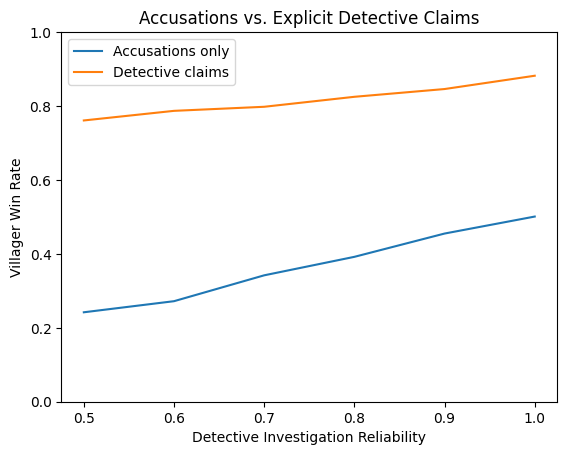

In [35]:
claim_num_games = 1000 #Increase after checking the example
claim_reliabilities = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
claim_discussion_rounds = 3
claim_seed = 42
claim_comparison_results = {}

claim_random_state = random.getstate()
try:
  for claim_label, claim_game_class in [("Accusations only", Game), ("Detective claims", ClaimGame)]:
    claim_comparison_results[claim_label] = {}
    for claim_reliability in tqdm(claim_reliabilities, desc=claim_label):
      claim_wins = 0
      for claim_i in range(claim_num_games):
        random.seed(claim_seed + claim_i)
        claim_game = claim_game_class(claim_reliability, claim_discussion_rounds)
        claim_result = claim_game.play()
        if claim_result["winner"] == "Villager":
          claim_wins += 1
      claim_comparison_results[claim_label][claim_reliability] = claim_wins / claim_num_games
finally:
  random.setstate(claim_random_state)

plt.figure()
for claim_label, claim_rates in claim_comparison_results.items():
  plt.plot(list(claim_rates.keys()), list(claim_rates.values()), label=claim_label)
plt.xlabel("Detective Investigation Reliability")
plt.ylabel("Villager Win Rate")
plt.title("Accusations vs. Explicit Detective Claims")
plt.ylim(0,1)
plt.legend()
plt.show()


The comparison changes both messages and the inference needed to interpret role claims. It evaluates the complete extension, not the isolated causal effect of wording. Results depend on the fixed claiming policies and approximate accusation model. Values below q=0.5 remain available in the earlier experiments; this new comparison starts at uninformative signals and ends at accurate signals.

### Evaluation 


Accusations only
Reliability | Village wins | Voting accuracy | Identification accuracy
0.50        | 0.242        | 0.330           | 0.339
0.60        | 0.272        | 0.364           | 0.369
0.70        | 0.342        | 0.427           | 0.429
0.80        | 0.392        | 0.471           | 0.474
0.90        | 0.455        | 0.533           | 0.535
1.00        | 0.501        | 0.576           | 0.576

Detective claims
Reliability | Village wins | Voting accuracy | Identification accuracy
0.50        | 0.761        | 0.843           | 0.843
0.60        | 0.787        | 0.859           | 0.859
0.70        | 0.798        | 0.866           | 0.866
0.80        | 0.825        | 0.883           | 0.883
0.90        | 0.846        | 0.900           | 0.900
1.00        | 0.882        | 0.922           | 0.922


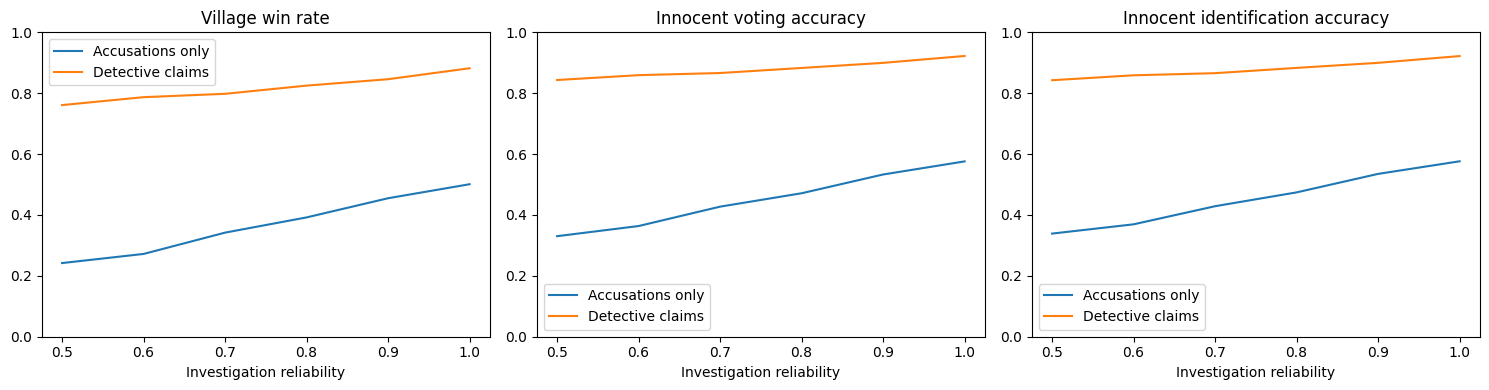

In [36]:
evaluation_num_games = 1000
evaluation_rounds = 3
evaluation_reliabilities = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
evaluation_seed = 42
evaluation_results = {}

evaluation_random_state = random.getstate()
try:
  for evaluation_label, evaluation_class in [("Accusations only", Game), ("Detective claims", ClaimGame)]:
    evaluation_results[evaluation_label] = {}

    for evaluation_reliability in evaluation_reliabilities:
      evaluation_wins = 0
      evaluation_correct_votes = 0
      evaluation_identifications = 0
      evaluation_innocent_count = 0

      for evaluation_i in range(evaluation_num_games):
        random.seed(evaluation_seed + evaluation_i)
        evaluation_game = evaluation_class(evaluation_reliability, evaluation_rounds)
        evaluation_result = evaluation_game.play()

        if evaluation_result["winner"] == "Villager":
          evaluation_wins += 1

        #Score after play; ground truth is used only for evaluation
        for evaluation_agent in evaluation_game.villagers + [evaluation_game.detective]:
          evaluation_innocent_count += 1
          if evaluation_result["votes"][evaluation_agent.id] == evaluation_game.mafia_id:
            evaluation_correct_votes += 1

          evaluation_max = max(evaluation_agent.beliefs)
          evaluation_targets = [p for p in evaluation_game.players if evaluation_agent.beliefs[p] == evaluation_max]
          if evaluation_game.mafia_id in evaluation_targets:
            evaluation_identifications += 1 / len(evaluation_targets)

      evaluation_results[evaluation_label][evaluation_reliability] = {
        "Village win rate": evaluation_wins / evaluation_num_games,
        "Innocent voting accuracy": evaluation_correct_votes / evaluation_innocent_count,
        "Innocent identification accuracy": evaluation_identifications / evaluation_innocent_count
      }
finally:
  random.setstate(evaluation_random_state)

for evaluation_label, evaluation_rates in evaluation_results.items():
  print("\n" + evaluation_label)
  print("Reliability | Village wins | Voting accuracy | Identification accuracy")
  for evaluation_reliability, evaluation_metrics in evaluation_rates.items():
    print(f"{evaluation_reliability:.2f}        | {evaluation_metrics['Village win rate']:.3f}        | {evaluation_metrics['Innocent voting accuracy']:.3f}           | {evaluation_metrics['Innocent identification accuracy']:.3f}")

evaluation_fig, evaluation_axes = plt.subplots(1, 3, figsize=(15, 4))
for evaluation_ax, evaluation_metric in zip(evaluation_axes, ["Village win rate", "Innocent voting accuracy", "Innocent identification accuracy"]):
  for evaluation_label, evaluation_rates in evaluation_results.items():
    evaluation_ax.plot(list(evaluation_rates.keys()), [m[evaluation_metric] for m in evaluation_rates.values()], label=evaluation_label)
  evaluation_ax.set_title(evaluation_metric)
  evaluation_ax.set_xlabel("Investigation reliability")
  evaluation_ax.set_ylim(0, 1)
  evaluation_ax.legend()

plt.tight_layout()
plt.show()